In [5]:
import pandas as pd
import numpy as np

CTA_delays = pd.read_csv('/Users/kylesahadeo/Documents/TechTeam/bus_delay_notices.csv')
CTA_delays.head()

,Bus Route,Delay Notice Time,Delay End Notice Time,Time Delayed,Notes
0,55,"October 13, 2025 at 8:07 PM","October 13, 2025 at 9:13 PM",1:06,Reroute due to fire department activity; south...
1,79,"October 14, 2025 at 4:33 AM","October 14, 2025 at 5:40 AM",1:07,Reroute due to blockage
2,71,"October 14, 2025 at 7:44 AM","October 14, 2025 at 8:53 AM",1:09,Reroute due to blockage; southbound buses not ...
3,86,"October 14, 2025 at 10:05 AM","October 14, 2025 at 1:47 PM",3:42,Reroute due to blockage; southbound buses not ...
4,34,"October 14, 2025 at 4:35 PM","October 14, 2025 at 5:50 PM",1:15,Reroute due to blockage


In [6]:
CTA_delays.info()

<class 'pandas.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Bus Route              457 non-null    str  
 1   Delay Notice Time      457 non-null    str  
 2   Delay End Notice Time  457 non-null    str  
 3   Time Delayed           457 non-null    str  
 4   Notes                  457 non-null    str  
dtypes: str(5)
memory usage: 62.5 KB


In [7]:
CTA_delays = CTA_delays.assign(
    time_minutes=lambda x: pd.to_timedelta(x['Time Delayed'] + ":00").dt.total_seconds() / 60
)

CTA_delays.head()

,Bus Route,Delay Notice Time,Delay End Notice Time,Time Delayed,Notes,time_minutes
0,55,"October 13, 2025 at 8:07 PM","October 13, 2025 at 9:13 PM",1:06,Reroute due to fire department activity; south...,66.0
1,79,"October 14, 2025 at 4:33 AM","October 14, 2025 at 5:40 AM",1:07,Reroute due to blockage,67.0
2,71,"October 14, 2025 at 7:44 AM","October 14, 2025 at 8:53 AM",1:09,Reroute due to blockage; southbound buses not ...,69.0
3,86,"October 14, 2025 at 10:05 AM","October 14, 2025 at 1:47 PM",3:42,Reroute due to blockage; southbound buses not ...,222.0
4,34,"October 14, 2025 at 4:35 PM","October 14, 2025 at 5:50 PM",1:15,Reroute due to blockage,75.0


In [8]:
avg_all_routes = CTA_delays["time_minutes"].mean()

print(avg_all_routes)

390.88402625820567


In [25]:
median_all_routes = CTA_delays["time_minutes"].median()
print(median_all_routes)

193.0


In [9]:
CTA_delays = CTA_delays.assign(
    time_minutes=lambda x: pd.to_timedelta(x['Time Delayed'] + ":00").dt.total_seconds() / 60
)

CTA_delays.head()

,Bus Route,Delay Notice Time,Delay End Notice Time,Time Delayed,Notes,time_minutes
0,55,"October 13, 2025 at 8:07 PM","October 13, 2025 at 9:13 PM",1:06,Reroute due to fire department activity; south...,66.0
1,79,"October 14, 2025 at 4:33 AM","October 14, 2025 at 5:40 AM",1:07,Reroute due to blockage,67.0
2,71,"October 14, 2025 at 7:44 AM","October 14, 2025 at 8:53 AM",1:09,Reroute due to blockage; southbound buses not ...,69.0
3,86,"October 14, 2025 at 10:05 AM","October 14, 2025 at 1:47 PM",3:42,Reroute due to blockage; southbound buses not ...,222.0
4,34,"October 14, 2025 at 4:35 PM","October 14, 2025 at 5:50 PM",1:15,Reroute due to blockage,75.0


In [10]:
avg_delay = CTA_delays.groupby("Bus Route")["time_minutes"].mean()
print(avg_delay)

Bus Route
1       315.000000
103     580.333333
106     483.000000
108     137.000000
111     344.000000
          ...     
96      330.000000
97      210.500000
J14    1602.250000
X49     296.500000
X9      329.750000
Name: time_minutes, Length: 105, dtype: float64


In [26]:
median_delay = CTA_delays.groupby("Bus Route")["time_minutes"].median()
print(median_delay)

Bus Route
1      315.0
103    601.0
106    483.0
108    137.0
111    344.0
       ...  
96     330.0
97     210.5
J14    287.5
X49    296.5
X9     313.5
Name: time_minutes, Length: 105, dtype: float64


Text(0, 0.5, 'Average Delay in Minutes')

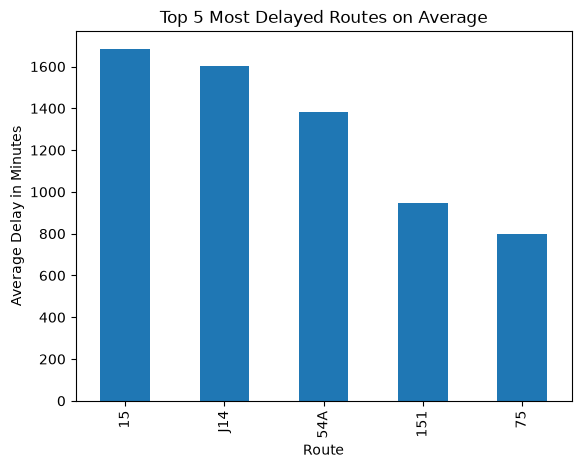

In [32]:
avg_delay_top5 = avg_delay.sort_values(ascending = False).head(5)

avg_graph = avg_delay_top5.plot(kind="bar",x="Bus Route",y="time_minutes")
avg_graph.set_title("Top 5 Most Delayed Routes on Average") 
avg_graph.set_xlabel("Route")
avg_graph.set_ylabel("Average Delay in Minutes")


Text(0, 0.5, 'Average Delay in Minutes')

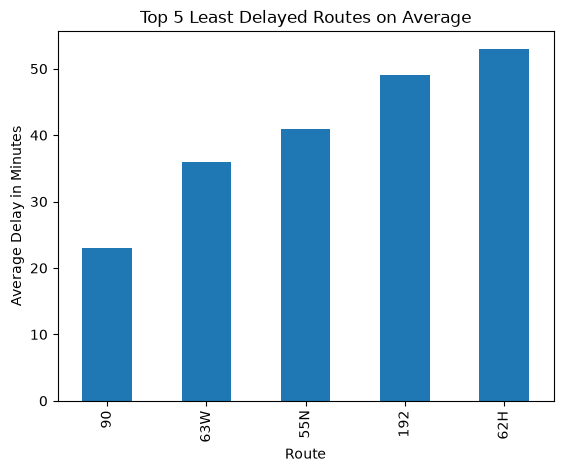

In [31]:
avg_delay_bottom5 = avg_delay.sort_values(ascending = True).head(5)

avg_graph = avg_delay_bottom5.plot(kind="bar",x="Bus Route",y="time_minutes")
avg_graph.set_title("Top 5 Least Delayed Routes on Average") 
avg_graph.set_xlabel("Route")
avg_graph.set_ylabel("Average Delay in Minutes")


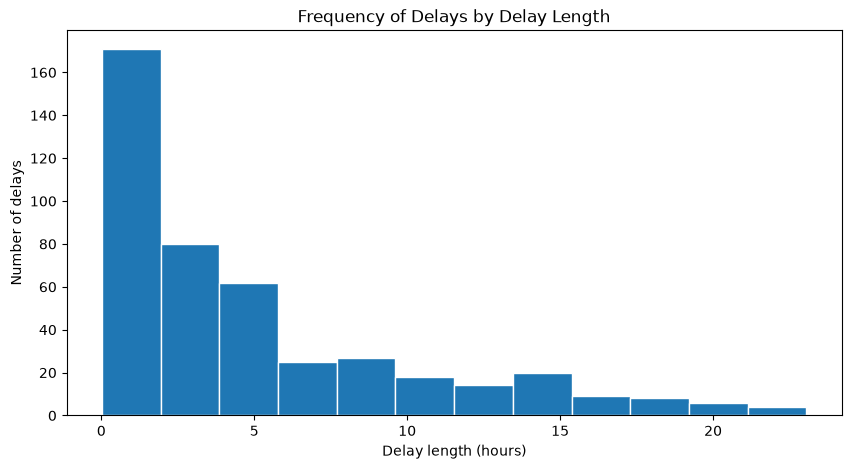

In [33]:
import matplotlib.pyplot as plt 

CTA_delays[CTA_delays["time_minutes"] <= 24 * 60]["time_minutes"].div(60).plot(
    kind="hist", bins=12, edgecolor="white", figsize=(10, 5)
)
plt.title("Frequency of Delays by Delay Length")
plt.xlabel("Delay length (hours)")
plt.ylabel("Number of delays")
plt.show()